w = 7.670319819795388 b = 0.7685468732199224
BCE sau 1000 lần lặp = 0.06625177338029256


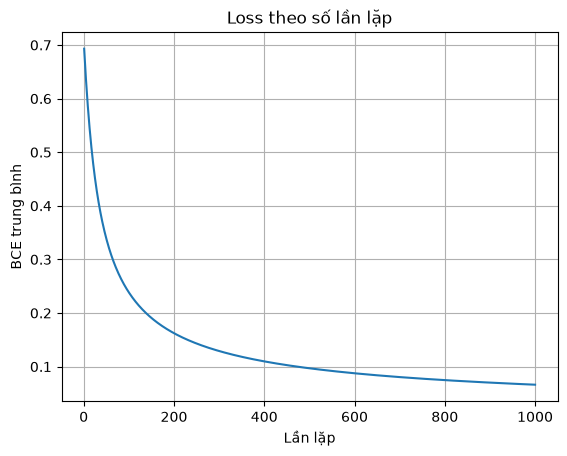

In [1]:
import numpy as np
import matplotlib.pyplot as plt
 
x_raw = np.array([132,141,88,154,151,102,119,106,102,143,76,168,94,186], dtype=float)
y = np.array([1,1,0,1,1,0,0,0,0,1,0,1,0,1], dtype=float)
x = (x_raw - 130) / 50
 
def sigmoid(z):
    # Tính ổn định cho cả z dương lớn và z âm lớn
    p = np.empty_like(z, dtype=float)
    positive = z >= 0
    p[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    p[~positive] = exp_z / (1 + exp_z)
    return p
 
def bce_mean(z, y):
    # BCE trung bình, tránh log(0)
    return np.mean(np.logaddexp(0, z) - y*z)
 
w, b, alpha = 0.0, 0.0, 0.2
loss_history = []
for iteration in range(1000):
    z = w*x + b
    p = sigmoid(z)
    loss_history.append(bce_mean(z, y))
    dw = np.mean((p-y)*x)
    db = np.mean(p-y)
    # Cập nhật đồng thời bằng gradient vừa tính
    w_new = w - alpha*dw
    b_new = b - alpha*db
    w, b = w_new, b_new
 
z_final = w*x + b
final_loss = bce_mean(z_final, y)
print('w =', w, 'b =', b)
print('BCE sau 1000 lần lặp =', final_loss)
 
plt.plot(range(1, 1001), loss_history)
plt.xlabel('Lần lặp')
plt.ylabel('BCE trung bình')
plt.title('Loss theo số lần lặp')
plt.grid(True)
plt.show()
